In [13]:
import seaborn as sns
df = sns.load_dataset("diamonds")
print(df.shape)
df.shape
df.info()
df

(53940, 10)
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [4]:
import numpy as np
import pandas as pd
import seaborn as sns   # 시각적 자료의 통계 부분 담당
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"

In [5]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [6]:
df.describe()
print("평균:", round(df["price"].mean(),0))
print("중앙값:", round(df["price"].median(),0))

평균: 3933.0
중앙값: 2401.0


In [ ]:
print("x_0:", (df["x"] == 0).sum(), "y_0:", (df["y"] == 0).sum(), "z_0:", (df["z"] == 0).sum())
df["cut"].value_counts()
bad = (df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)
df = df[~bad]

df.shape

x_0: 0 y_0: 0 z_0: 0
y,z 20이상: 3


(53920, 10)

In [ ]:
bad = (df["y"] > 20) | (df["z"] > 20)
df[bad]
# 특정 값이 높아 불균형하다.
df_clean = df[~bad].copy()
df_clean.shape


(53917, 10)

<function matplotlib.pyplot.show(close=None, block=None)>

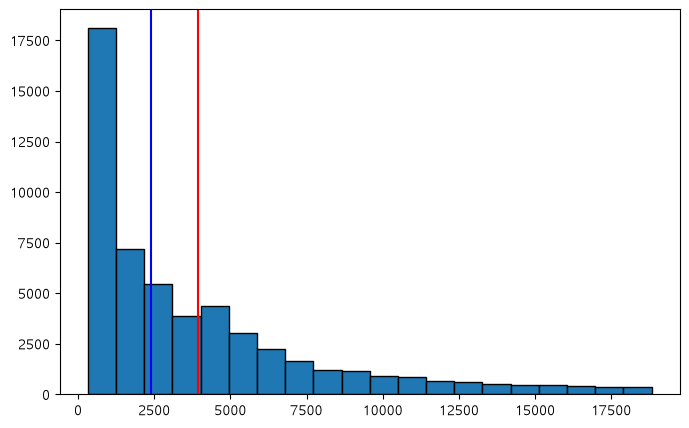

In [51]:
import matplotlib.pyplot as plt

plt.subplots(figsize=(8,5))
plt.hist(df_clean["price"], bins=20, edgecolor="black")

plt.axvline(df_clean["price"].mean(), color="red")
plt.axvline(df_clean["price"].median(), color="blue")

plt.show

In [56]:
df_sample = df_clean.sample(3000, random_state=42)

상관관계: 0.92


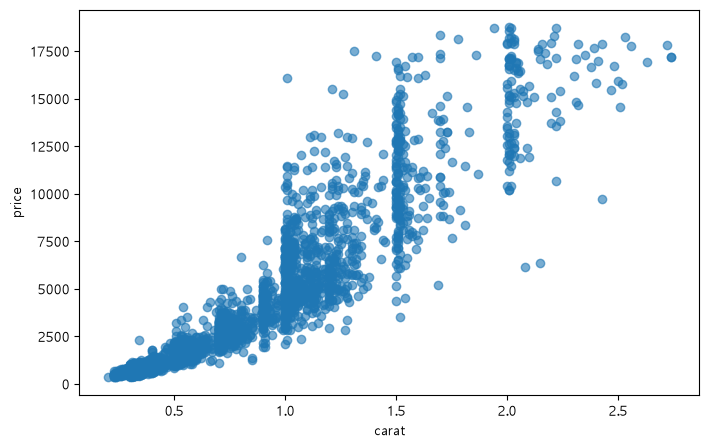

In [58]:
df["carat"].sort_values(ascending=False)

plt.subplots(figsize=(8,5))

plt.scatter(df_sample["carat"], df_sample["price"], alpha=0.6)
plt.xlabel("carat")
plt.ylabel("price")

print("상관관계:", round(df_sample["carat"].corr(df_sample["price"]),2))